# Stage 4 – Segment-Level Profit Thresholds

Turns the calibrated probabilities into contact rules and tests **RQ3 / H1**: does one threshold per value segment earn more campaign profit than one threshold for everyone?

**Design:**
1. One **primary model**, fixed in advance as the model with the highest out-of-fold profit under one global threshold; the other four models are replications.
2. Rules compared (chosen on training data, applied once to the test set): **P0** 0.5; **P1** one profit-optimal threshold; **P2** one threshold per segment; theoretical thresholds; the **per-customer rule** (contact if expected profit > 0).
3. H1 test on the primary model: paired bootstrap of P2 − P1; other models with Holm correction.
4. Extra analyses: threshold stability, CLV tertiles vs K-Means segments, contact budgets, cost sensitivity, k = 4.

## Step 1 – Setup and data

In [1]:
# Cell 1 - Setup
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

import config as C
from src import modelling as M

train = pd.read_csv(C.PROCESSED_DIR / "train_segmented.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test_segmented.csv")
oof = pd.read_csv(C.PROCESSED_DIR / "stage3_oof_predictions.csv")
tst = pd.read_csv(C.PROCESSED_DIR / "stage3_test_predictions.csv")
assert (oof[C.ID_COL] == train[C.ID_COL]).all() and (tst[C.ID_COL] == test[C.ID_COL]).all()

SEGMENTS = ["Low-value", "New high-value", "Established high-value"]
MODELS = ["Logistic regression", "Random forest", "LightGBM", "SVM", "TabICL v2"]

# Calibration selected in Stage 3 / 3b (lowest cross-validated Brier score), no weights
chosen = (pd.read_csv(C.TABLES_DIR / "15_cv_selected_calibration.csv")
          .query("condition == 'none'").set_index("model")["calibration"].to_dict())
chosen["TabICL v2"] = pd.read_csv(C.TABLES_DIR / "20_tabicl_cv_calibration.csv").set_index("calibration")["Brier"].idxmin()
P_TR = {m: oof[f"{m}|none|{chosen[m]}"].to_numpy() for m in MODELS}
P_TE = {m: tst[f"{m}|none|{chosen[m]}"].to_numpy() for m in MODELS}

y_tr, y_te = train[C.TARGET].to_numpy(), test[C.TARGET].to_numpy()
clv_tr, clv_te = M.customer_value(train), M.customer_value(test)
seg_tr, seg_te = train["segment"].to_numpy(), test["segment"].to_numpy()
D = clv_tr.mean() * C.INCENTIVE_RATIO
GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)
N_BOOT_THRESHOLD = 200

COLOURS = {"Logistic regression": "#2a78d6", "Random forest": "#1baf7a", "LightGBM": "#eda100",
           "SVM": "#4a3aa7", "TabICL v2": "#d6402a"}
SEG_COLOURS = {"Low-value": "#2a78d6", "New high-value": "#1baf7a", "Established high-value": "#4a3aa7"}
GREY = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png"); print("Saved figure:", name)
def save_table(df, name):
    df.to_csv(C.TABLES_DIR / f"{name}.csv"); print("Saved table:", name)

print("Calibration used:", chosen)
print(f"Train {len(train):,} | test {len(test):,} | incentive d = {D:.2f} | thresholds tried: {GRID[0]}–{GRID[-1]}")

Calibration used: {'Logistic regression': 'raw', 'Random forest': 'Platt', 'LightGBM': 'raw', 'SVM': 'isotonic', 'TabICL v2': 'Platt'}
Train 5,625 | test 1,407 | incentive d = 39.00 | thresholds tried: 0.01–0.99


## Step 2 – Helper functions
Profit of a threshold = sum of the gains of everyone above it. Each threshold is the **median of the optima of 200 bootstrap resamples** of the training (OOF) predictions.

In [2]:
# Cell 2 - Profit, threshold search and policy evaluation
def gains(y, clv, d=D, gamma=None, f=None):
    benefit, cost = M.profit_terms(clv, d, f, gamma)
    return np.where(np.asarray(y) == 1, benefit, -cost)

def profit_curve(p, g):
    # total profit for every threshold in GRID (vectorised)
    return ((p[None, :] > GRID[:, None]) * g[None, :]).sum(axis=1)

def choose_threshold(p, g, n_boot=N_BOOT_THRESHOLD):
    rng = np.random.default_rng(C.RANDOM_STATE)   # same resamples every call -> reproducible thresholds
    best = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, len(p), len(p))
        best[b] = GRID[np.argmax(profit_curve(p[idx], g[idx]))]
    return float(np.round(np.median(best), 2)), best

def segment_thresholds(p, g, seg, groups):
    out, boot = {}, {}
    for s in groups:
        m = seg == s
        out[s], boot[s] = choose_threshold(p[m], g[m])
    return out, boot

def decide(p, seg=None, threshold=None, by_segment=None):
    if by_segment is not None:
        t = np.array([by_segment[s] for s in seg])
        return p > t
    return p > threshold

def outcome(y, contact, clv, d=D, gamma=None, f=None):
    # business measures for one set of decisions
    g = gains(y, clv, d, gamma, f)
    y = np.asarray(y); n_contact = contact.sum()
    profit = float((contact * g).sum())
    cost = M.campaign_cost(y, contact, clv, d, f, gamma)
    return {"Profit per customer": profit / len(y),
            "Targeted share": contact.mean(),
            "Recall (churners reached)": (contact & (y == 1)).sum() / max(y.sum(), 1),
            "Precision": (contact & (y == 1)).sum() / max(n_contact, 1),
            "ROI": profit / cost if cost > 0 else np.nan}

def boot_diff(y, cA, cB, clv, d=D, gamma=None, f=None):
    # paired bootstrap of the profit-per-customer difference A - B on the same customers
    g = gains(y, clv, d, gamma, f)
    cA, cB = np.asarray(cA, int), np.asarray(cB, int)
    stat = lambda i: ((cA[i] - cB[i]) * g[i]).mean()
    return M.paired_bootstrap(stat, len(y))
print("Helpers ready.")

Helpers ready.


## Step 3 – Thresholds chosen on the training data (all five models)
P1 (one threshold), P2 (one per segment) and the theoretical thresholds from the profit formula.

In [3]:
# Cell 3 - Thresholds per model
g_tr, g_te = gains(y_tr, clv_tr), gains(y_te, clv_te)
theory_global = float(M.theoretical_threshold(np.array([clv_tr.mean()]), D)[0])
theory_seg = {s: float(M.theoretical_threshold(np.array([clv_tr[seg_tr == s].mean()]), D)[0]) for s in SEGMENTS}

TH, BOOT = {}, {}
for m in MODELS:
    t1, b1 = choose_threshold(P_TR[m], g_tr)
    t2, b2 = segment_thresholds(P_TR[m], g_tr, seg_tr, SEGMENTS)
    TH[m] = {"P1": t1, "P2": t2}
    BOOT[m] = {"P1": b1, "P2": b2}

rows = [{"model": m, "P1 global": TH[m]["P1"], **{f"P2 {s}": TH[m]["P2"][s] for s in SEGMENTS}} for m in MODELS]
rows.append({"model": "Theory (profit formula)", "P1 global": theory_global,
             **{f"P2 {s}": theory_seg[s] for s in SEGMENTS}})
thresholds = pd.DataFrame(rows).set_index("model")
save_table(thresholds.round(3), "25_thresholds_by_model")
thresholds.round(3)

Saved table: 25_thresholds_by_model


,P1 global,P2 Low-value,P2 New high-value,P2 Established high-value
model,,,,
Logistic regression,0.180,0.280,0.190,0.090
Random forest,0.150,0.310,0.190,0.090
LightGBM,0.180,0.230,0.170,0.160
SVM,0.140,0.310,0.170,0.100
TabICL v2,0.180,0.240,0.190,0.100
Theory (profit formula),0.153,0.327,0.134,0.115


## Step 4 – The primary model
Highest training (OOF) profit under P1. The test set is not used for this choice.

In [4]:
# Cell 4 - Primary model
oof_p1 = {m: outcome(y_tr, decide(P_TR[m], threshold=TH[m]["P1"]), clv_tr)["Profit per customer"] for m in MODELS}
PRIMARY = max(oof_p1, key=oof_p1.get)
print(pd.Series(oof_p1, name="OOF profit per customer under P1").round(3).to_string())
print("\nPrimary model:", PRIMARY)

Logistic regression    50.469
Random forest          50.627
LightGBM               51.228
SVM                    50.118
TabICL v2              50.873

Primary model: LightGBM


## Step 5 – Test-set results of every rule (single evaluation)
P0 (> 0.5), P1, P2, theoretical thresholds and the per-customer rule.

In [5]:
# Cell 5 - All rules, all models, test set
def policies(m, p, seg, clv):
    return {
        "P0 (0.5)": decide(p, threshold=0.5),
        "P1 global": decide(p, threshold=TH[m]["P1"]),
        "P2 segment": decide(p, seg, by_segment=TH[m]["P2"]),
        "Theory global": decide(p, threshold=theory_global),
        "Theory segment": decide(p, seg, by_segment=theory_seg),
        "Per customer (E>0)": M.contact_decision(p, clv, D),
    }
POL_TE = {m: policies(m, P_TE[m], seg_te, clv_te) for m in MODELS}
POL_TR = {m: policies(m, P_TR[m], seg_tr, clv_tr) for m in MODELS}

res = pd.DataFrame([{"model": m, "rule": r, **outcome(y_te, c, clv_te)}
                    for m in MODELS for r, c in POL_TE[m].items()]).set_index(["model", "rule"])
print("Reference points (test): contact nobody = 0.00 | contact everyone = "
      f"{outcome(y_te, np.ones(len(y_te), bool), clv_te)['Profit per customer']:.2f} | perfect knowledge = "
      f"{outcome(y_te, y_te == 1, clv_te)['Profit per customer']:.2f}")
save_table(res.round(4), "26_test_results_by_rule")
res.round(3)

Reference points (test): contact nobody = 0.00 | contact everyone = 37.58 | perfect knowledge = 66.95
Saved table: 26_test_results_by_rule


Profit per customer  Targeted share  \
model               rule                                                      
Logistic regression P0 (0.5)                         38.408           0.237   
                    P1 global                        47.418           0.518   
                    P2 segment                       49.360           0.522   
                    Theory global                    47.988           0.560   
                    Theory segment                   49.479           0.513   
                    Per customer (E>0)               49.361           0.520   
Random forest       P0 (0.5)                         34.363           0.215   
                    P1 global                        48.960           0.560   
                    P2 segment                       48.691           0.528   
                    Theory global                    48.883           0.555   
                    Theory segment                   50.201           0.513   
                    Per customer (E>0)               49.762           0.520   
LightGBM            P0 (0.5)                         35.485           0.220   
                    P1 global                        48.370           0.520   
                    P2 segment                       49.018           0.517   
                    Theory global                    49.325           0.551   
                    Theory segment                   50.341           0.524   
                    Per customer (E>0)               49.896           0.515   
SVM                 P0 (0.5)                         33.141           0.195   
                    P1 global                        47.989           0.598   
                    P2 segment                       49.226           0.510   
                    Theory global                    47.599           0.572   
                    Theory segment                   49.337           0.524   
                    Per customer (E>0)               49.121           0.512   
TabICL v2           P0 (0.5)                         33.562           0.213   
                    P1 global                        48.687           0.526   
                    P2 segment                       50.121           0.544   
                    Theory global                    49.353           0.557   
                    Theory segment                   49.943           0.524   
                    Per customer (E>0)               49.322           0.525   

                                        Recall (churners reached)  Precision  \
model               rule                                                       
Logistic regression P0 (0.5)                                0.578      0.647   
                    P1 global                               0.872      0.447   
                    P2 segment                              0.861      0.438   
                    Theory global                           0.904      0.429   
                    Theory segment                          0.861      0.446   
                    Per customer (E>0)                      0.861      0.440   
Random forest       P0 (0.5)                                0.524      0.647   
                    P1 global                               0.912      0.433   
                    P2 segment                              0.856      0.431   
                    Theory global                           0.909      0.435   
                    Theory segment                          0.869      0.450   
                    Per customer (E>0)                      0.861      0.440   
LightGBM            P0 (0.5)                                0.543      0.657   
                    P1 global                               0.880      0.449   
                    P2 segment                              0.877      0.451   
                    Theory global                           0.912      0.440   
                    Theory segment                          0.880      

Saved figure: 14_test_profit_by_rule


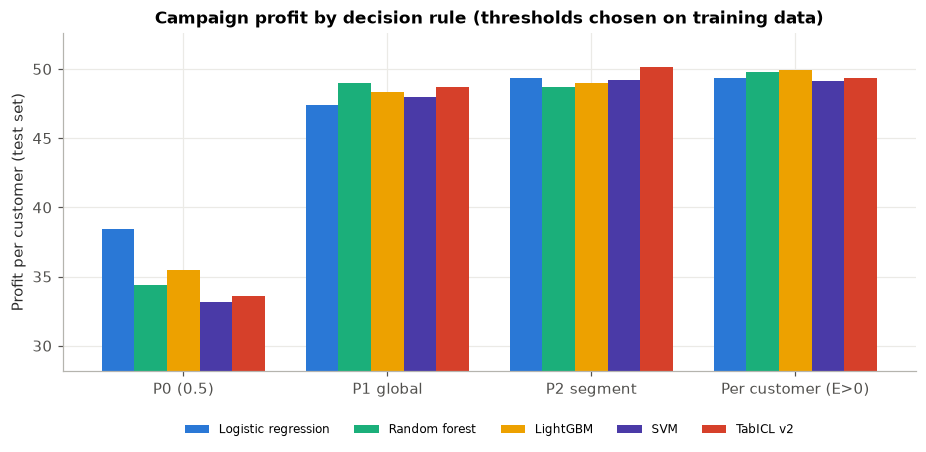

In [6]:
# Cell 6 - Figure: test profit per customer by rule and model
rules = ["P0 (0.5)", "P1 global", "P2 segment", "Per customer (E>0)"]
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.16
for j, m in enumerate(MODELS):
    vals = [res.loc[(m, r), "Profit per customer"] for r in rules]
    ax.bar(np.arange(len(rules)) + (j - 2) * w, vals, w, color=COLOURS[m], label=m)
ax.set_xticks(np.arange(len(rules)), rules)
ax.set_ylabel("Profit per customer (test set)")
ax.set_ylim(bottom=min(res["Profit per customer"].min() - 5, 30))
ax.set_title("Campaign profit by decision rule (thresholds chosen on training data)")
ax.legend(ncols=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save(fig, "14_test_profit_by_rule")
plt.show()

## Step 6 – H1: segment thresholds (P2) vs one threshold (P1)
Confirmatory test on the primary model: paired bootstrap (2,000 resamples) of P2 − P1, plus the number of changed decisions per segment. Secondary: other models and P2 − P0 (Holm).

In [7]:
# Cell 7 - H1 tests
rows = []
for m in MODELS:
    c0, c1, c2 = (POL_TE[m][r] for r in ("P0 (0.5)", "P1 global", "P2 segment"))
    for label, cA, cB in (("P2 - P1", c2, c1), ("P2 - P0", c2, c0)):
        obs, lo, hi, p = boot_diff(y_te, cA, cB, clv_te)
        rows.append({"model": m, "comparison": label, "role": "confirmatory" if (m == PRIMARY and label == "P2 - P1") else "secondary",
                     "difference per customer": obs, "CI 2.5%": lo, "CI 97.5%": hi, "p": p,
                     "decisions changed": int((cA != cB).sum())})
h1 = pd.DataFrame(rows)
sec = (h1["role"] == "secondary").to_numpy()
sig = np.zeros(len(h1), dtype=bool)
sig[sec] = M.holm(h1.loc[sec, "p"])
sig[~sec] = h1.loc[~sec, "p"].to_numpy() < 0.05
h1["significant (Holm for secondary)"] = sig
save_table(h1.set_index(["model", "comparison"]).round(4), "27_h1_tests")
h1.set_index(["model", "comparison"]).round(3)

Saved table: 27_h1_tests


role  difference per customer  \
model               comparison                                          
Logistic regression P2 - P1        secondary                    1.942   
                    P2 - P0        secondary                   10.952   
Random forest       P2 - P1        secondary                   -0.269   
                    P2 - P0        secondary                   14.328   
LightGBM            P2 - P1     confirmatory                    0.649   
                    P2 - P0        secondary                   13.533   
SVM                 P2 - P1        secondary                    1.237   
                    P2 - P0        secondary                   16.085   
TabICL v2           P2 - P1        secondary                    1.435   
                    P2 - P0        secondary                   16.559   

                                CI 2.5%  CI 97.5%      p  decisions changed  \
model               comparison                                                
Logistic regression P2 - P1       0.241     3.821  0.030                130   
                    P2 - P0       7.116    14.953  0.000                401   
Random forest       P2 - P1      -1.817     1.322  0.696                145   
                    P2 - P0      10.135    18.918  0.000                440   
LightGBM            P2 - P1      -0.267     1.693  0.179                 41   
                    P2 - P0       9.592    18.071  0.000                418   
SVM                 P2 - P1       0.280     2.116  0.017                123   
                    P2 - P0      11.700    20.792  0.000                443   
TabICL v2           P2 - P1      -0.058     3.081  0.065                 92   
                    P2 - P0      12.152    21.218  0.000                466   

                                significant (Holm for secondary)  
model               comparison                                    
Logistic regression P2 - P1                                False  
                    P2 - P0                                 True  
Random forest       P2 - P1                                False  
                    P2 - P0                                 True  
LightGBM            P2 - P1                                False  
                    P2 - P0                                 True  
SVM                 P2 - P1                                False  
                    P2 - P0                                 True  
TabICL v2           P2 - P1                                False  
                    P2 - P0                                 True

In [8]:
# Cell 8 - Where does the P2 - P1 difference come from? (primary model, test set)
c1, c2 = POL_TE[PRIMARY]["P1 global"], POL_TE[PRIMARY]["P2 segment"]
rows = []
for s in SEGMENTS:
    m = seg_te == s
    rows.append({"segment": s, "customers": m.sum(), "P1 threshold": TH[PRIMARY]["P1"],
                 "P2 threshold": TH[PRIMARY]["P2"][s], "decisions changed": int((c1[m] != c2[m]).sum()),
                 "profit difference (share of total per customer)": ((c2[m].astype(int) - c1[m]) * g_te[m]).sum() / len(y_te),
                 "P1 targeted": c1[m].mean(), "P2 targeted": c2[m].mean()})
breakdown = pd.DataFrame(rows).set_index("segment")
save_table(breakdown.round(4), "28_h1_breakdown_by_segment")
breakdown.round(3)

Saved table: 28_h1_breakdown_by_segment


,customers,P1 threshold,P2 threshold,decisions changed,profit difference (share of total per customer),P1 targeted,P2 targeted
segment,,,,,,,
Low-value,446,0.18,0.23,23,0.112,0.265,0.213
New high-value,523,0.18,0.17,8,0.083,0.874,0.889
Established high-value,438,0.18,0.16,10,0.454,0.358,0.381


## Step 7 – Optimism gap and share captured
- **Optimism gap:** P2 − P1 gain on the training predictions minus the gain on the test set.
- **Share captured:** (P2 − P1) / (per-customer rule − P1).

In [9]:
# Cell 9 - Optimism gap and share captured
rows = []
for m in MODELS:
    def pp(pol, y, clv, r): return outcome(y, pol[r], clv)["Profit per customer"]
    tr = {r: pp(POL_TR[m], y_tr, clv_tr, r) for r in ("P1 global", "P2 segment", "Per customer (E>0)")}
    te = {r: pp(POL_TE[m], y_te, clv_te, r) for r in ("P1 global", "P2 segment", "Per customer (E>0)")}
    gain_tr, gain_te = tr["P2 segment"] - tr["P1 global"], te["P2 segment"] - te["P1 global"]
    full_te = te["Per customer (E>0)"] - te["P1 global"]
    rows.append({"model": m, "P2-P1 training (in-sample)": gain_tr, "P2-P1 test": gain_te,
                 "optimism gap": gain_tr - gain_te,
                 "per-customer - P1 (test)": full_te,
                 "share captured by P2 (test)": gain_te / full_te if abs(full_te) > 1e-9 else np.nan})
ladder = pd.DataFrame(rows).set_index("model")
save_table(ladder.round(4), "29_optimism_gap_and_share")
ladder.round(3)

Saved table: 29_optimism_gap_and_share


,P2-P1 training (in-sample),P2-P1 test,optimism gap,per-customer - P1 (test),share captured by P2 (test)
model,,,,,
Logistic regression,0.880,1.942,-1.062,1.943,1.000
Random forest,1.090,-0.269,1.359,0.801,-0.336
LightGBM,0.501,0.649,-0.148,1.526,0.425
SVM,1.681,1.237,0.444,1.132,1.093
TabICL v2,0.836,1.435,-0.599,0.635,2.258


## Step 8 – Are the chosen thresholds stable?
The 200 bootstrap optima per segment, with the theoretical threshold marked.

Saved figure: 15_thresholds_profit_curves_stability


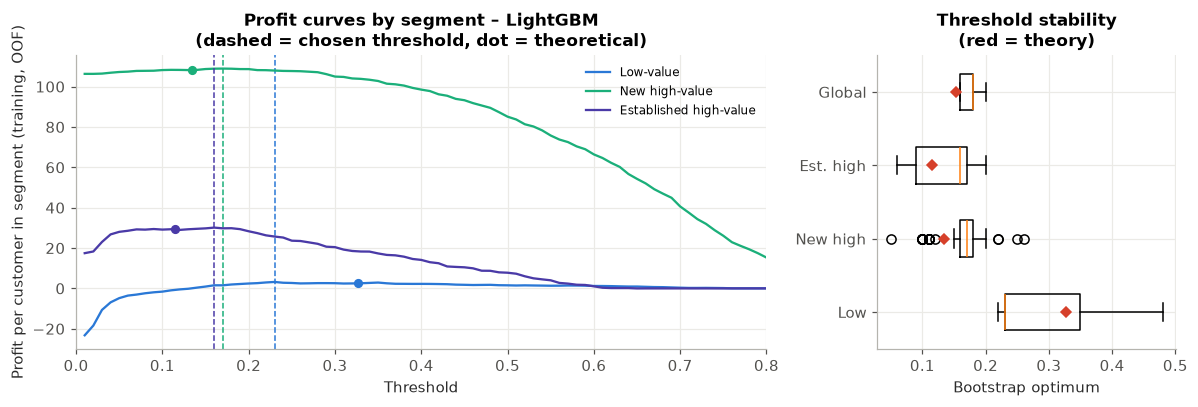

Saved table: 30_threshold_stability


,chosen,theory,bootstrap 2.5%,bootstrap 97.5%
Low-value,0.23,0.327,0.23,0.35
New high-value,0.17,0.134,0.10,0.20
Established high-value,0.16,0.115,0.07,0.19
Global (P1),0.18,0.153,0.16,0.19


In [10]:
# Cell 10 - Threshold stability
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1.3]})
ax = axes[0]
for i, s in enumerate(SEGMENTS):
    m = seg_tr == s
    curve = profit_curve(P_TR[PRIMARY][m], g_tr[m]) / m.sum()
    ax.plot(GRID, curve, color=SEG_COLOURS[s], label=s)
    ax.axvline(TH[PRIMARY]["P2"][s], color=SEG_COLOURS[s], ls="--", lw=1)
    ax.plot(theory_seg[s], curve[np.abs(GRID - theory_seg[s]).argmin()], "o", color=SEG_COLOURS[s], ms=5)
ax.set_xlabel("Threshold"); ax.set_ylabel("Profit per customer in segment (training, OOF)")
ax.set_title(f"Profit curves by segment – {PRIMARY}\n(dashed = chosen threshold, dot = theoretical)")
ax.legend(fontsize=8); ax.set_xlim(0, 0.8)
ax = axes[1]
data = [BOOT[PRIMARY]["P2"][s] for s in SEGMENTS] + [BOOT[PRIMARY]["P1"]]
ax.boxplot(data, orientation="horizontal", widths=0.5)
ax.set_yticks(range(1, 5), ["Low", "New high", "Est. high", "Global"])
for i, t in enumerate([theory_seg[s] for s in SEGMENTS] + [theory_global], start=1):
    ax.plot(t, i, "D", color="#d6402a", ms=5)
ax.set_xlabel("Bootstrap optimum"); ax.set_title("Threshold stability\n(red = theory)")
fig.tight_layout(); save(fig, "15_thresholds_profit_curves_stability"); plt.show()

stab = pd.DataFrame({k: {"chosen": TH[PRIMARY]["P2"][k] if k in SEGMENTS else TH[PRIMARY]["P1"],
                         "theory": theory_seg.get(k, theory_global),
                         "bootstrap 2.5%": np.percentile(v, 2.5), "bootstrap 97.5%": np.percentile(v, 97.5)}
                     for k, v in list(BOOT[PRIMARY]["P2"].items()) + [("Global (P1)", BOOT[PRIMARY]["P1"])]}).T
save_table(stab.round(3), "30_threshold_stability")
stab.round(3)

## Step 9 – K-Means segments vs CLV tertiles
Repeats the experiment with three CLV tertiles (as in Maldonado et al., 2021). Expected beforehand: tertiles perform equal or better, because the profit threshold depends on customer value.

In [11]:
# Cell 11 - CLV tertiles
cuts = np.quantile(train["MonthlyCharges"], [1 / 3, 2 / 3])
tert_tr = np.digitize(train["MonthlyCharges"], cuts).astype(str)
tert_te = np.digitize(test["MonthlyCharges"], cuts).astype(str)
TERT = ["0", "1", "2"]
t_tert, _ = segment_thresholds(P_TR[PRIMARY], g_tr, tert_tr, TERT)
c_tert = decide(P_TE[PRIMARY], tert_te, by_segment=t_tert)
c_km, c_g = POL_TE[PRIMARY]["P2 segment"], POL_TE[PRIMARY]["P1 global"]
rows = {"K-Means segments (P2)": outcome(y_te, c_km, clv_te),
        "CLV tertiles": outcome(y_te, c_tert, clv_te),
        "One global threshold (P1)": outcome(y_te, c_g, clv_te)}
basis = pd.DataFrame(rows).T
obs, lo, hi, p = boot_diff(y_te, c_tert, c_km, clv_te)
print(f"CLV tertile cut points (monthly charge): {cuts.round(2)} | thresholds: {t_tert}")
print(f"Tertiles - K-Means: {obs:+.3f} per customer (95% CI {lo:+.3f} to {hi:+.3f}, p = {p:.3f})")
save_table(basis.round(4), "31_segmentation_basis")
basis.round(3)

CLV tertile cut points (monthly charge): [50.6  84.17] | thresholds: {'0': 0.23, '1': 0.18, '2': 0.11}
Tertiles - K-Means: +0.394 per customer (95% CI -0.646 to +1.595, p = 0.510)
Saved table: 31_segmentation_basis


,Profit per customer,Targeted share,Recall (churners reached),Precision,ROI
K-Means segments (P2),49.018,0.517,0.877,0.451,3.427
CLV tertiles,49.412,0.527,0.882,0.445,3.370
One global threshold (P1),48.370,0.520,0.880,0.449,3.353


## Step 10 – Contact budgets
If only 10%, 20% or 30% of customers can be contacted: rank by churn probability or by expected profit (Lemmens & Gupta, 2020)?

Saved table: 32_budget_scenarios
Saved figure: 16_budget_scenarios


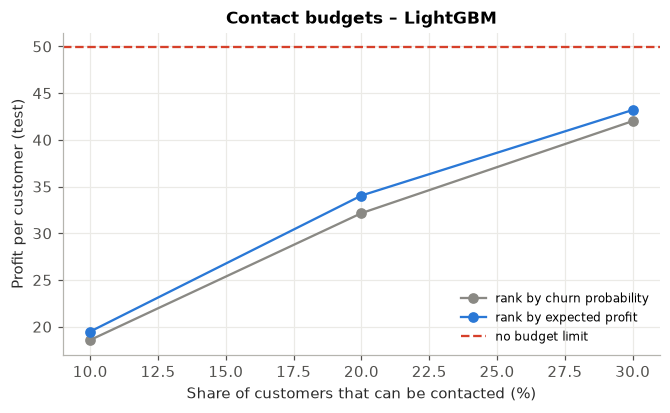

Profit per customer  Targeted share  \
budget   ranking                                                          
10%      rank by churn probability               18.579           0.100   
         rank by expected profit                 19.485           0.100   
20%      rank by churn probability               32.157           0.200   
         rank by expected profit                 34.043           0.200   
30%      rank by churn probability               42.012           0.300   
         rank by expected profit                 43.199           0.300   
no limit per-customer rule (E>0)                 49.896           0.515   

                                    Recall (churners reached)  Precision  \
budget   ranking                                                           
10%      rank by churn probability                      0.273      0.723   
         rank by expected profit                        0.259      0.688   
20%      rank by churn probability                      0.495      0.658   
         rank by expected profit                        0.473      0.630   
30%      rank by churn probability                      0.663      0.588   
         rank by expected profit                        0.634      0.562   
no limit per-customer rule (E>0)                        0.861      0.444   

                                      ROI  share Low-value  \
budget   ranking                                             
10%      rank by churn probability  9.155            0.043   
         rank by expected profit    9.163            0.000   
20%      rank by churn probability  7.310            0.064   
         rank by expected profit    7.475            0.000   
30%      rank by churn probability  5.847            0.064   
         rank by expected profit    5.839            0.005   
no limit per-customer rule (E>0)    3.474            0.081   

                                    share New high-value  \
budget   ranking                                           
10%      rank by churn probability                 0.957   
         rank by expected profit                   0.936   
20%      rank by churn probability                 0.893   
         rank by expected profit                   0.858   
30%      rank by churn probability                 0.820   
         rank by expected profit                   0.789   
no limit per-customer rule (E>0)                   0.643   

                                    share Established high-value  
budget   ranking                                                  
10%      rank by churn probability                         0.000  
         rank by expected profit                           0.064  
20%      rank by churn probability                         0.043  
         rank by expected profit                           0.142  
30%      rank by churn probability                         0.116  
         rank by expected profit                           0.206  
no limit per-customer rule (E>0)                           0.276

In [12]:
# Cell 12 - Budget scenarios
p = P_TE[PRIMARY]
benefit, cost = M.profit_terms(clv_te, D)
exp_profit = p * benefit - (1 - p) * cost
rows = []
for cap in (0.10, 0.20, 0.30):
    k = int(round(cap * len(p)))
    for label, score in (("rank by churn probability", p), ("rank by expected profit", exp_profit)):
        contact = np.zeros(len(p), bool); contact[np.argsort(-score)[:k]] = True
        r = outcome(y_te, contact, clv_te)
        rows.append({"budget": f"{int(cap*100)}%", "ranking": label, **r,
                     **{f"share {s}": contact[seg_te == s].sum() / k for s in SEGMENTS}})
unc = POL_TE[PRIMARY]["Per customer (E>0)"]
rows.append({"budget": "no limit", "ranking": "per-customer rule (E>0)", **outcome(y_te, unc, clv_te),
             **{f"share {s}": unc[seg_te == s].sum() / unc.sum() for s in SEGMENTS}})
budget = pd.DataFrame(rows).set_index(["budget", "ranking"])
save_table(budget.round(4), "32_budget_scenarios")

fig, ax = plt.subplots(figsize=(7, 3.8))
for label, colour in (("rank by churn probability", GREY), ("rank by expected profit", "#2a78d6")):
    vals = [budget.loc[(f"{c}%", label), "Profit per customer"] for c in (10, 20, 30)]
    ax.plot([10, 20, 30], vals, "o-", color=colour, label=label)
ax.axhline(budget.loc[("no limit", "per-customer rule (E>0)"), "Profit per customer"], color="#d6402a", ls="--",
           label="no budget limit")
ax.set_xlabel("Share of customers that can be contacted (%)"); ax.set_ylabel("Profit per customer (test)")
ax.set_title(f"Contact budgets – {PRIMARY}"); ax.legend(fontsize=8)
save(fig, "16_budget_scenarios"); plt.show()
budget.round(3)

## Step 11 – Sensitivity to the cost assumptions
Thresholds are re-chosen on training data for: offer cost $d$ = CLV/20 (base), /10, /5; acceptance rate $\gamma$ = 0.1, 0.3 (base), 0.5; proportional offer $d_i = 0.05 \times \mathit{CLV}_i$.

Saved table: 33_sensitivity
Saved figure: 17_sensitivity


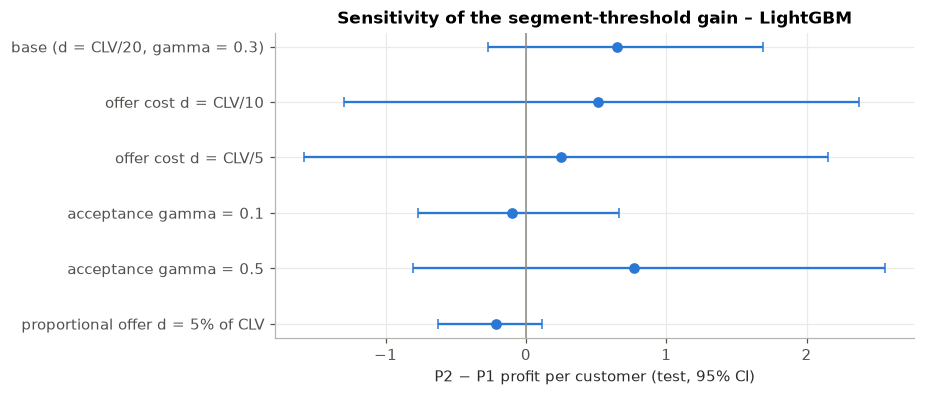

,P1 threshold,P2 Low-value,P2 New high-value,P2 Established high-value,P1 profit,P2 profit,P2 - P1,CI 2.5%,CI 97.5%
scenario,,,,,,,,,
"base (d = CLV/20, gamma = 0.3)",0.18,0.23,0.17,0.16,48.370,49.018,0.649,-0.267,1.693
offer cost d = CLV/10,0.24,0.52,0.27,0.19,35.124,35.634,0.511,-1.300,2.375
offer cost d = CLV/5,0.41,0.58,0.38,0.37,21.868,22.115,0.247,-1.581,2.156
acceptance gamma = 0.1,0.35,0.58,0.31,0.27,10.626,10.526,-0.101,-0.772,0.667
acceptance gamma = 0.5,0.08,0.23,0.10,0.05,91.069,91.841,0.772,-0.805,2.561
proportional offer d = 5% of CLV,0.18,0.22,0.18,0.18,46.744,46.531,-0.212,-0.625,0.112


In [13]:
# Cell 13 - Sensitivity
p_tr, p_te = P_TR[PRIMARY], P_TE[PRIMARY]
scenarios = {
    "base (d = CLV/20, gamma = 0.3)": dict(d_tr=D, d_te=D, gamma=None),
    "offer cost d = CLV/10": dict(d_tr=clv_tr.mean() / 10, d_te=clv_tr.mean() / 10, gamma=None),
    "offer cost d = CLV/5": dict(d_tr=clv_tr.mean() / 5, d_te=clv_tr.mean() / 5, gamma=None),
    "acceptance gamma = 0.1": dict(d_tr=D, d_te=D, gamma=0.1),
    "acceptance gamma = 0.5": dict(d_tr=D, d_te=D, gamma=0.5),
    "proportional offer d = 5% of CLV": dict(d_tr=0.05 * clv_tr, d_te=0.05 * clv_te, gamma=None),
}
rows = []
for name, sc in scenarios.items():
    gtr = gains(y_tr, clv_tr, sc["d_tr"], sc["gamma"])
    t1, _ = choose_threshold(p_tr, gtr)
    t2, _ = segment_thresholds(p_tr, gtr, seg_tr, SEGMENTS)
    c1, c2 = decide(p_te, threshold=t1), decide(p_te, seg_te, by_segment=t2)
    obs, lo, hi, pv = boot_diff(y_te, c2, c1, clv_te, sc["d_te"], sc["gamma"])
    rows.append({"scenario": name, "P1 threshold": t1, **{f"P2 {s}": t2[s] for s in SEGMENTS},
                 "P1 profit": outcome(y_te, c1, clv_te, sc["d_te"], sc["gamma"])["Profit per customer"],
                 "P2 profit": outcome(y_te, c2, clv_te, sc["d_te"], sc["gamma"])["Profit per customer"],
                 "P2 - P1": obs, "CI 2.5%": lo, "CI 97.5%": hi})
sens = pd.DataFrame(rows).set_index("scenario")
save_table(sens.round(4), "33_sensitivity")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
yy = np.arange(len(sens))[::-1]
ax.errorbar(sens["P2 - P1"], yy, xerr=[sens["P2 - P1"] - sens["CI 2.5%"], sens["CI 97.5%"] - sens["P2 - P1"]],
            fmt="o", color="#2a78d6", capsize=3)
ax.axvline(0, color=GREY, lw=1)
ax.set_yticks(yy, sens.index); ax.set_xlabel("P2 − P1 profit per customer (test, 95% CI)")
ax.set_title(f"Sensitivity of the segment-threshold gain – {PRIMARY}")
save(fig, "17_sensitivity"); plt.show()
sens.round(3)

## Step 12 – Robustness: four segments instead of three (descriptive only, primary model)

In [14]:
# Cell 14 - k = 4
seg4_tr, seg4_te = train["segment_k4"].to_numpy(), test["segment_k4"].to_numpy()
SEG4 = sorted(pd.unique(seg4_tr))
t4, _ = segment_thresholds(P_TR[PRIMARY], g_tr, seg4_tr, SEG4)
c4 = decide(P_TE[PRIMARY], seg4_te, by_segment=t4)
obs, lo, hi, pv = boot_diff(y_te, c4, POL_TE[PRIMARY]["P1 global"], clv_te)
k4 = pd.DataFrame({"k = 4 segments": outcome(y_te, c4, clv_te),
                   "k = 3 segments (P2)": outcome(y_te, POL_TE[PRIMARY]["P2 segment"], clv_te),
                   "one threshold (P1)": outcome(y_te, POL_TE[PRIMARY]["P1 global"], clv_te)}).T
print("k = 4 thresholds:", t4)
print(f"k = 4 vs P1: {obs:+.3f} per customer (95% CI {lo:+.3f} to {hi:+.3f})")
save_table(k4.round(4), "34_k4_robustness")
k4.round(3)

k = 4 thresholds: {'Established high-value': 0.16, 'Established low-value': 0.23, 'New high-value': 0.17, 'New low-value': 0.23}
k = 4 vs P1: +0.415 per customer (95% CI -0.419 to +1.367)
Saved table: 34_k4_robustness


,Profit per customer,Targeted share,Recall (churners reached),Precision,ROI
k = 4 segments,48.785,0.507,0.866,0.454,3.489
k = 3 segments (P2),49.018,0.517,0.877,0.451,3.427
one threshold (P1),48.370,0.520,0.880,0.449,3.353


## Step 13 – Per-segment results of the primary model (input for the Stage 5 KPIs)

In [15]:
# Cell 15 - Per-segment outcomes for each rule
rows = []
for r in ("P0 (0.5)", "P1 global", "P2 segment", "Per customer (E>0)"):
    c = POL_TE[PRIMARY][r]
    for s in SEGMENTS:
        m = seg_te == s
        rows.append({"rule": r, "segment": s, "customers": m.sum(), **outcome(y_te[m], c[m], clv_te[m])})
by_seg = pd.DataFrame(rows).set_index(["rule", "segment"])
save_table(by_seg.round(4), "35_primary_by_segment")
by_seg.round(3)

Saved table: 35_primary_by_segment


customers  Profit per customer  \
rule               segment                                                  
P0 (0.5)           Low-value                     446                1.954   
                   New high-value                523               85.228   
                   Established high-value        438               10.231   
P1 global          Low-value                     446                1.861   
                   New high-value                523              106.317   
                   Established high-value        438               26.534   
P2 segment         Low-value                     446                2.214   
                   New high-value                523              106.540   
                   Established high-value        438               27.992   
Per customer (E>0) Low-value                     446                2.776   
                   New high-value                523              107.953   
                   Established high-value        438               28.553   

                                           Targeted share  \
rule               segment                                  
P0 (0.5)           Low-value                        0.043   
                   New high-value                   0.518   
                   Established high-value           0.043   
P1 global          Low-value                        0.265   
                   New high-value                   0.874   
                   Established high-value           0.358   
P2 segment         Low-value                        0.213   
                   New high-value                   0.889   
                   Established high-value           0.381   
Per customer (E>0) Low-value                        0.132   
                   New high-value                   0.891   
                   Established high-value           0.457   

                                           Recall (churners reached)  \
rule               segment                                             
P0 (0.5)           Low-value                                   0.222   
                   New high-value                              0.700   
                   Established high-value                      0.209   
P1 global          Low-value                                   0.796   
                   New high-value                              0.945   
                   Established high-value                      0.701   
P2 segment         Low-value                                   0.685   
                   New high-value                              0.953   
                   Established high-value                      0.746   
Per customer (E>0) Low-value                                   0.463   
                   New high-value                              0.960   
                   Established high-value                      0.806   

                                           Precision     ROI  
rule               segment                                    
P0 (0.5)           Low-value                   0.632   2.016  
                   New high-value              0.653   7.419  
                   Established high-value      0.737  11.861  
P1 global          Low-value                   0.364   0.234  
                   New high-value              0.523   4.730  
                   Established high-value      0.299   2.326  
P2 segment         Low-value                   0.389   0.354  
                   New high-value              0.518   4.635  
                   Established high-value      0.299   2.307  
Per customer (E>0) Low-value                   0.424   0.738  
                   New high-value              0.521   4.703  
                   Established high-value      0.270   1.916

## Step 14 – Save for Stage 5

In [16]:
# Cell 16 - Save the decision rules
joblib.dump({"primary_model": PRIMARY, "calibration": chosen, "thresholds": TH,
             "theory_global": theory_global, "theory_segment": theory_seg, "incentive_d": D},
            C.MODELS_DIR / "stage4_thresholds.joblib")
print("Saved outputs/models/stage4_thresholds.joblib")

Saved outputs/models/stage4_thresholds.joblib


## Findings
**1. The big gain is using a profit threshold at all:** every profit rule earns 11–17 more per customer than 0.5 (all significant). At 0.5 about 20% of customers are contacted and half the churners are missed; profit rules contact about half and reach 85–90% of churners.

**2. H1 is not supported.** LightGBM (primary): P2 − P1 = **+0.65 per customer** (95% CI −0.27 to +1.69; p = 0.18); only 41 of 1,407 decisions changed. Other models: LR +1.94, TabICL +1.43, SVM +1.24, RF −0.27; none significant after Holm.

**3. Thresholds:** global 0.18; segments 0.23 / 0.17 / 0.16 (theory 0.15; 0.33 / 0.13 / 0.12). The theoretical segment thresholds gave the highest or near-highest test profit for every model (LightGBM 50.3). The low-value curve is flat (bootstrap optimum 0.23–0.35).

**4. No systematic optimism:** training gain not consistently larger than test gain (gap −1.1 to +1.4).

**5. CLV tertiles:** 49.4 vs 49.0 per customer for K-Means segments (not significant).

**6. Budgets:** ranking by expected profit beats ranking by churn probability at every budget (e.g. 34.0 vs 32.2 at 20%), moving contacts to established high-value customers.

**7. Sensitivity:** the P2 − P1 interval always includes zero; with a proportional offer the gain disappears (−0.21); k = 4 gives the same picture (48.8).

**Carried forward to Stage 5:** LightGBM with its segment thresholds.